# Hotelling Model: Endogenous Entry and Exit (SPE with Color Tracking)

In [44]:
import matplotlib.pyplot as plt
import numpy as np

# PARAMETERS
X_MIN = -1.0  # left boundary of the market
X_MAX = 1.0   # right boundary of the market
N_CONS = 401  # number of consumers on the grid
V = 4  # consumer reservation value
t = 1.0  # transport cost per unit distance

c0 = 1  # marginal cost
cF = 0.04  # fixed cost per period

dp = 0.1  # price adjustment step (optimized for global search speed)
dx = 0.02  # location adjustment step
p_max = V  # maximum admissible price

B0 = 0.50  # initial buffer of a firm
ENTRY_COST = 0.30  # sunk entry cost
ENTRY_EVERY = 1  # entry frequency
MAX_FIRMS = 1000 # cap on simultaneous firms
ENTRY_MARGIN = 0.0  # minimum expected profit to enter

T = 1000  # simulation periods
SEED = 42

rng = np.random.default_rng(SEED)

# Consumer grid (total mass = 1)
z = np.linspace(X_MIN, X_MAX, N_CONS)
mass = 1.0 / N_CONS

In [45]:
# DEMAND AND PROFITS (N firms) - Fixed Tie-Breaker
def calculate_profit(x, p):
    x = np.asarray(x, dtype=float)
    p = np.asarray(p, dtype=float)
    n = len(x)

    if n == 0:
        return np.array([]), np.array([])

    # Calculate total cost for all consumers across all firms
    full_price = p[:, None] + t * np.abs(x[:, None] - z[None, :])
    min_cost = np.min(full_price, axis=0)
    served = (V - min_cost) >= 0

    # Exact tie breaking
    is_winner = np.isclose(full_price, min_cost)
    tie_counts = np.sum(is_winner, axis=0)

    q = np.zeros(n)
    for i in range(n):
        q[i] = np.sum((is_winner[i] & served) / tie_counts) * mass

    profits = (p - c0) * q - cF
    return profits, q

In [46]:
# GLOBAL SEARCH IN PRICE (Vectorized)
def best_price_global(x, p, firm):
    prices = np.arange(c0, p_max + dp/2, dp)
    n_prices = len(prices)
    n_firms = len(x)
    
    # Expand arrays to evaluate all possible prices simultaneously
    p_matrix = np.repeat(p[:, None], n_prices, axis=1)
    p_matrix[firm, :] = prices
    
    x_col = x[:, None, None]
    p_col = p_matrix[:, :, None]
    z_row = z[None, None, :]
    
    full_price = p_col + t * np.abs(x_col - z_row)
    min_cost = np.min(full_price, axis=0)
    is_winner = np.isclose(full_price, min_cost[None, :, :])
    tie_counts = np.sum(is_winner, axis=0)
    served = (V - min_cost) >= 0
    
    q_firm = np.sum((is_winner[firm] & served) / tie_counts, axis=1) * mass
    profits_firm = (prices - c0) * q_firm - cF
    
    best_idx = np.argmax(profits_firm)
    return prices[best_idx]

In [47]:
# INNER LOOP: PRICE EQUILIBRIUM
def price_equilibrium(x, p_init, max_iter=20):
    p_current = p_init.copy()
    for _ in range(max_iter):
        p_old = p_current.copy()
        for i in range(len(x)):
            p_current[i] = best_price_global(x, p_current, i)
        if np.allclose(p_current, p_old):
            break
    return p_current

# OUTER LOOP: BEST LOCATION (Evaluated via Subgame Perfect Equilibrium)
def best_location_global_spe(x, p, firm):
    best_x = x[firm]
    
    # Base profit at current location using converged prices
    p_eq_current = price_equilibrium(x, p)
    best_profit = calculate_profit(x, p_eq_current)[0][firm]

    # Global search: Evaluate every discrete point across the entire market
    x_grid = np.arange(X_MIN, X_MAX + dx/2, dx)

    for new_x in x_grid:
        # Skip evaluating the exact same position again
        if np.isclose(new_x, x[firm]):
            continue
            
        x_test = x.copy()
        x_test[firm] = new_x
        
        # Look ahead to inner subgame equilibrium for this new location
        p_eq_test = price_equilibrium(x_test, p_eq_current) 
        new_profit = calculate_profit(x_test, p_eq_test)[0][firm]

        if new_profit > best_profit:
            best_profit = new_profit
            best_x = new_x

    return best_x

In [48]:
# FIRM ENTRY AND EXIT (Now tracking Firm IDs for coloring)
def update_buffers(buffer, profits):
    return buffer + profits

def exit_firms(x, p, buffer, firm_ids):
    alive = buffer >= 0.0
    return x[alive], p[alive], buffer[alive], firm_ids[alive], np.where(~alive)[0]

def evaluate_entry_spe(x, p):
    # Scan the exact same global grid used for firm movement
    x_grid = np.arange(X_MIN, X_MAX + dx/2, dx)
    best = (None, None, -np.inf)

    for xe in x_grid:
        x_test = np.append(x, xe)
        # Smart warm start: copy average price or V/2
        p_guess = np.mean(p) if len(p) > 0 else V/2
        p_test = np.append(p, p_guess)
        
        p_eq = price_equilibrium(x_test, p_test)
        pi_e = calculate_profit(x_test, p_eq)[0][-1]

        if pi_e > best[2]:
            best = (xe, p_eq[-1], pi_e)

    return best

def try_entry(x, p, buffer, firm_ids, next_firm_id):
    if len(x) >= MAX_FIRMS:
        return x, p, buffer, firm_ids, next_firm_id, False

    # Remove the n_x parameter constraint here
    xe, pe, pi_e = evaluate_entry_spe(x, p)

    if pi_e > ENTRY_MARGIN:
        x = np.append(x, xe)
        p = np.append(p, pe)
        buffer = np.append(buffer, B0 - ENTRY_COST)
        firm_ids = np.append(firm_ids, next_firm_id)
        next_firm_id += 1
        return x, p, buffer, firm_ids, next_firm_id, True

    return x, p, buffer, firm_ids, next_firm_id, False

In [49]:
# SIMULATION
def simulate(n_firms_0=2, T=T, adjust_location=True, verbose=True):
    x = np.linspace(X_MIN / 2, X_MAX / 2, n_firms_0)
    p = np.full(n_firms_0, c0 + 0.5)
    buffer = np.full(n_firms_0, B0)
    
    # Initialize unique IDs for starting firms
    firm_ids = np.arange(n_firms_0)
    next_firm_id = n_firms_0

    hist = {
        "n_firms": [],
        "prices": [],
        "locations": [],
        "profits": [],
        "buffers": [],
        "entries": [],
        "exits": [],
        "firm_ids": []  # New tracker for plotting colors
    }

    for step in range(T):
        # Outer Loop: Location (Subgame Perfect)
        if adjust_location and len(x) > 0:
            for i in rng.permutation(len(x)):
                x[i] = best_location_global_spe(x, p, i)
        
        # Inner Loop: Final Price Equilibrium for this step
        p = price_equilibrium(x, p)
        
        # Accounting
        profits, q = calculate_profit(x, p)
        buffer = update_buffers(buffer, profits)

        # Exit routine passes and filters firm_ids as well
        x, p, buffer, firm_ids, gone = exit_firms(x, p, buffer, firm_ids)
        if verbose and len(gone) > 0:
            print(f"t={step:4d}  {len(gone)} firm(s) exit -> {len(x)} remaining")

        entered = False
        if step % ENTRY_EVERY == 0:
            x, p, buffer, firm_ids, next_firm_id, entered = try_entry(x, p, buffer, firm_ids, next_firm_id)
            if verbose and entered:
                print(f"t={step:4d}  1 firm enters at x={x[-1]:.2f}, p={p[-1]:.2f} (Firm ID: {firm_ids[-1]}) -> total {len(x)}")

        hist["n_firms"].append(len(x))
        hist["prices"].append(p.copy())
        hist["locations"].append(x.copy())
        hist["firm_ids"].append(firm_ids.copy())
        
        if len(x) > 0:
            hist["profits"].append(calculate_profit(x, p)[0].copy())
        else:
            hist["profits"].append(np.array([]))
            
        hist["buffers"].append(buffer.copy())
        hist["entries"].append(entered)
        hist["exits"].append(len(gone))

        if verbose and step % 5 == 0:
            print(f"Evaluated t={step} (Active firms: {len(x)})")
            
        if len(x) == 0:
            if verbose:
                print(f"t={step}: empty market, end of simulation.")
            break

    return x, p, buffer, firm_ids, hist

Starting simulation...
t=   0  1 firm enters at x=0.00, p=3.00 (Firm ID: 0) -> total 1
Evaluated t=0 (Active firms: 1)
t=   1  1 firm enters at x=-0.78, p=2.10 (Firm ID: 1) -> total 2
t=   2  1 firm enters at x=-0.30, p=1.50 (Firm ID: 2) -> total 3
t=   3  1 firm enters at x=-0.66, p=1.70 (Firm ID: 3) -> total 4
t=   4  1 firm enters at x=-0.26, p=1.20 (Firm ID: 4) -> total 5
t=   5  1 firm enters at x=-0.04, p=1.30 (Firm ID: 5) -> total 6
Evaluated t=5 (Active firms: 6)
t=   6  1 firm enters at x=0.20, p=1.30 (Firm ID: 6) -> total 7
Evaluated t=10 (Active firms: 7)
Evaluated t=15 (Active firms: 7)
Evaluated t=20 (Active firms: 7)
Evaluated t=25 (Active firms: 7)
Evaluated t=30 (Active firms: 7)
Evaluated t=35 (Active firms: 7)
Evaluated t=40 (Active firms: 7)
Evaluated t=45 (Active firms: 7)
Evaluated t=50 (Active firms: 7)
Evaluated t=55 (Active firms: 7)
Evaluated t=60 (Active firms: 7)
Evaluated t=65 (Active firms: 7)
Evaluated t=70 (Active firms: 7)
Evaluated t=75 (Active firms: 7

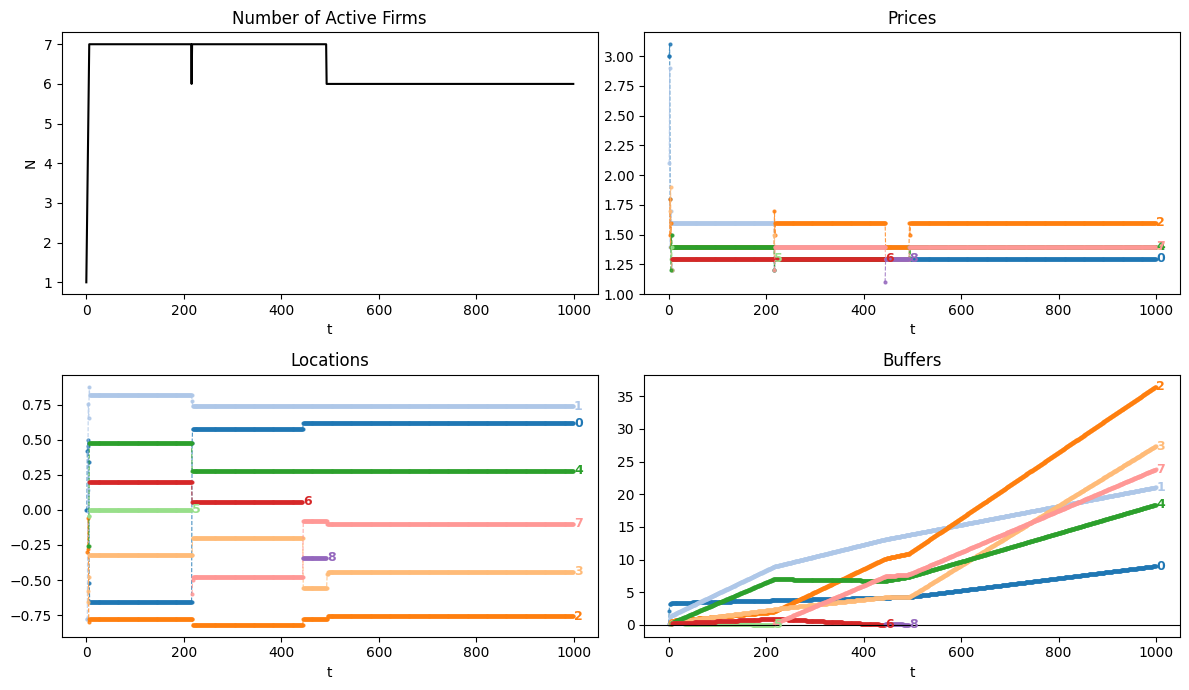

In [50]:
# PLOTS (Upgraded to group by Firm ID for unique colors)
def plot_results(hist):
    T_eff = len(hist["n_firms"])
    fig, ax = plt.subplots(2, 2, figsize=(12, 7))

    ax[0, 0].plot(hist["n_firms"], lw=1.5, color="black")
    ax[0, 0].set_title("Number of Active Firms")
    ax[0, 0].set_xlabel("t")
    ax[0, 0].set_ylabel("N")

    # Prepare a colormap (tab20 supports 20 distinct, cycling colors)
    cmap = plt.get_cmap("tab20")
    
    # Group the historical data by Firm ID so we can plot connected lines
    firm_data = {}
    for step in range(T_eff):
        f_ids = hist["firm_ids"][step]
        prices = hist["prices"][step]
        locs = hist["locations"][step]
        bufs = hist["buffers"][step]
        
        for i, f_id in enumerate(f_ids):
            if f_id not in firm_data:
                firm_data[f_id] = {"t": [], "p": [], "x": [], "b": []}
            firm_data[f_id]["t"].append(step)
            firm_data[f_id]["p"].append(prices[i])
            firm_data[f_id]["x"].append(locs[i])
            firm_data[f_id]["b"].append(bufs[i])

    # Plot each firm's trajectory in its own color and label it
    for f_id, data in firm_data.items():
        color = cmap(f_id % 20)  # Cycle through 20 colors safely
        
        # Plot the lines
        ax[0, 1].plot(data["t"], data["p"], marker='o', markersize=2, linestyle='--', linewidth=0.8, color=color, alpha=0.8)
        ax[1, 0].plot(data["t"], data["x"], marker='o', markersize=2, linestyle='--', linewidth=0.8, color=color, alpha=0.8)
        ax[1, 1].plot(data["t"], data["b"], marker='o', markersize=2, linestyle='--', linewidth=0.8, color=color, alpha=0.8)

        # Place the Firm ID text at the very last recorded point of that firm's life
        last_t = data["t"][-1]
        last_p = data["p"][-1]
        last_x = data["x"][-1]
        last_b = data["b"][-1]
        
        # Add a slight x-offset (+1.5) so the text doesn't overlap the final dot
        ax[0, 1].text(last_t + 1.5, last_p, str(f_id), color=color, fontsize=9, fontweight='bold', va='center')
        ax[1, 0].text(last_t + 1.5, last_x, str(f_id), color=color, fontsize=9, fontweight='bold', va='center')
        ax[1, 1].text(last_t + 1.5, last_b, str(f_id), color=color, fontsize=9, fontweight='bold', va='center')

    # Formatting
    ax[0, 1].set_title("Prices")
    ax[0, 1].set_xlabel("t")
    ax[1, 0].set_title("Locations")
    ax[1, 0].set_xlabel("t")
    ax[1, 1].axhline(0, color="k", lw=0.8)
    ax[1, 1].set_title("Buffers")
    ax[1, 1].set_xlabel("t")

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    print("Starting simulation...")
    x, p, buffer, firm_ids, hist = simulate(n_firms_0=0, T=T)

    print("\n--- Final State ---")
    print("Active firms:", len(x))

    pi, q = calculate_profit(x, p)
    for i in range(len(x)):
        print(
            f"  firm {firm_ids[i]}: x={x[i]:.3f}  p={p[i]:.3f}  "
            f"q={q[i]:.3f}  profit={pi[i]:+.4f}  buffer={buffer[i]:.3f}"
        )

    print("\nOpening results plot...")
    plot_results(hist)